# Crop water use and irrigation efficiency in an irrigated area
### Moulay Bousselham (Loukkos, Morocco) — FAO WaPOR v3 data, 2018-2025

**Research question.** In an irrigated area, do crops receive enough water, too much, or too little? Where, and at what time of the season?

**Study area.** A strip of about 6.5 × 3 km between the coastal dunes and the Merja Zerga lagoon, covered by WaPOR level 3 (20 m pixels, region "LOU").

**Data.**
| WaPOR variable | Meaning | Resolution |
|---|---|---|
| L3-AETI-D | Actual evapotranspiration and interception (ETa) | 20 m |
| L3-NPP-D | Net primary production (biomass) | 20 m |
| L1-RET-D | Reference evapotranspiration (ET0) | coarse |
| L1-PCP-D | Precipitation | coarse |

Land cover (LCC) is no longer available in WaPOR v3: it is replaced by the annual **Esri / Impact Observatory 10 m** land cover map and by a **manual digitisation of greenhouses**.

**Outline.**
0. Setup
1. Data download
2. Preparation: grid, land cover, masks, 2018-2025 cubes
3. The four indicators
4. Two-level K-means classification
5. Key figures
6. Conclusions and limitations


## 0. Setup

In [1]:
# Packages, Google Drive connection and project settings
!pip install wapordl rasterio pystac-client planetary-computer -q

import os, glob, json, calendar
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.patches import Patch
from rasterio.warp import reproject, Resampling, transform_bounds, transform_geom
from rasterio.transform import array_bounds
from rasterio.windows import from_bounds
from rasterio.features import rasterize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import wapordl
import pystac_client, planetary_computer
from google.colab import drive

drive.mount('/content/drive')

dossier_projet = "/content/drive/MyDrive/Projet_WaPOR"
dossier_data = dossier_projet + "/data"
region = dossier_projet + "/zone_moulay_bousselham.geojson"
fichier_serres = dossier_projet + "/serres_moulay_bousselham.geojson"
variables = ["L3-AETI-D", "L3-NPP-D", "L1-RET-D", "L1-PCP-D"]
annees = list(range(2018, 2026))
os.makedirs(dossier_data, exist_ok=True)
print("✅ Setup complete")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 3.4 MB/s eta 0:00:00


INFO: WaPORDL (`1.2.1`)


Mounted at /content/drive
✅ Setup complete


In [2]:
# Functions to read WaPOR data
def jours_par_decade(annee):
    """Number of days in each of the 36 dekads of the year (the 3rd dekad runs from day 21 to month end)."""
    jours = []
    for mois in range(1, 13):
        nb_jours_mois = calendar.monthrange(annee, mois)[1]
        jours += [10, 10, nb_jours_mois - 20]
    return np.array(jours)

def lire_variable(annee, var):
    """Reads a dekadal WaPOR variable and converts it to a per-dekad total (mm or gC/m²)."""
    fichier = glob.glob(f"{dossier_data}/{annee}/*{var}*.tif")[0]
    with rasterio.open(fichier) as src:
        donnees = src.read().astype(float)
        nodata = src.nodata
        echelles = np.array(src.scales).reshape(-1, 1, 1)
        decalages = np.array(src.offsets).reshape(-1, 1, 1)
        dates = src.descriptions
    if nodata is not None:
        donnees[donnees == nodata] = np.nan
    donnees = donnees * echelles + decalages                       # scale factor
    donnees = donnees * jours_par_decade(annee).reshape(-1, 1, 1)  # daily mean -> dekad total
    return donnees, dates

def grille_reference(annee):
    """Transform, coordinate reference system and size of the 20 m AETI grid."""
    f = glob.glob(f"{dossier_data}/{annee}/*L3-AETI-D*.tif")[0]
    with rasterio.open(f) as src:
        return src.transform, src.crs, src.height, src.width

def lire_sur_grille(annee, var):
    """Reads a variable, converts it and resamples it (nearest neighbour) onto the 20 m grid."""
    donnees, dates = lire_variable(annee, var)
    f = glob.glob(f"{dossier_data}/{annee}/*{var}*.tif")[0]
    with rasterio.open(f) as src:
        transform_src, crs_src = src.transform, src.crs
    transform_ref, crs_ref, hauteur, largeur = grille_reference(annee)
    if donnees.shape[1:] == (hauteur, largeur):
        return donnees, dates
    sortie = np.full((donnees.shape[0], hauteur, largeur), np.nan)
    reproject(source=donnees, destination=sortie,
              src_transform=transform_src, src_crs=crs_src,
              dst_transform=transform_ref, dst_crs=crs_ref,
              resampling=Resampling.nearest, src_nodata=np.nan, dst_nodata=np.nan)
    return sortie, dates

## 1. Data download (FAO WaPOR v3, `wapordl` package)

One folder per year, so that files do not overwrite each other (their names do not contain the date) and the download can resume after an interruption: files already present are skipped.

In [3]:
# Download 2018-2025 (resumes after an interruption)
for annee in annees:
    dossier_annee = f"{dossier_data}/{annee}"
    os.makedirs(dossier_annee, exist_ok=True)
    periode = [f"{annee}-01-01", f"{annee}-12-31"]
    for var in variables:
        deja = [nom for nom in os.listdir(dossier_annee) if var in nom and nom.endswith(".tif")]
        if deja:
            print(f"⏭️ {annee} {var} : already downloaded")
            continue
        try:
            f = wapordl.wapor_map(region, var, periode, dossier_annee)
            with rasterio.open(f) as src:
                print(f"✅ {annee} {var} : {src.count} dekads")
        except Exception as erreur:
            print(f"❌ {annee} {var} : {erreur}")

⏭️ 2018 L3-AETI-D : already downloaded
⏭️ 2018 L3-NPP-D : already downloaded
⏭️ 2018 L1-RET-D : already downloaded
⏭️ 2018 L1-PCP-D : already downloaded
⏭️ 2019 L3-AETI-D : already downloaded
⏭️ 2019 L3-NPP-D : already downloaded
⏭️ 2019 L1-RET-D : already downloaded
⏭️ 2019 L1-PCP-D : already downloaded
⏭️ 2020 L3-AETI-D : already downloaded
⏭️ 2020 L3-NPP-D : already downloaded
⏭️ 2020 L1-RET-D : already downloaded
⏭️ 2020 L1-PCP-D : already downloaded
⏭️ 2021 L3-AETI-D : already downloaded
⏭️ 2021 L3-NPP-D : already downloaded
⏭️ 2021 L1-RET-D : already downloaded
⏭️ 2021 L1-PCP-D : already downloaded
⏭️ 2022 L3-AETI-D : already downloaded
⏭️ 2022 L3-NPP-D : already downloaded
⏭️ 2022 L1-RET-D : already downloaded
⏭️ 2022 L1-PCP-D : already downloaded
⏭️ 2023 L3-AETI-D : already downloaded
⏭️ 2023 L3-NPP-D : already downloaded
⏭️ 2023 L1-RET-D : already downloaded
⏭️ 2023 L1-PCP-D : already downloaded
⏭️ 2024 L3-AETI-D : already downloaded
⏭️ 2024 L3-NPP-D : already downloaded
⏭️ 20

In [4]:
# Check: 8 years × 4 variables, 36 dekads each
problemes = 0
for annee in annees:
    for var in variables:
        fichiers = glob.glob(f"{dossier_data}/{annee}/*{var}*.tif")
        if not fichiers:
            print(f"❌ {annee} {var} : missing file")
            problemes += 1
        else:
            with rasterio.open(fichiers[0]) as src:
                if src.count != 36:
                    print(f"⚠️ {annee} {var} : only {src.count} dekads")
                    problemes += 1
print("Number of problems:", problemes)

Number of problems: 0


## 2. Data preparation

### 2.1 Reference grid and study area outline
WaPOR dekadal values are daily means: they are multiplied by the number of days in each dekad (8 to 11 days for the 3rd dekad of the month). Coarse-resolution precipitation and RET are resampled onto the 20 m AETI grid.

Grid: 324 × 155 pixels of 20 m
AETI 2023: mean 498 mm, min 108 mm, max 1219 mm


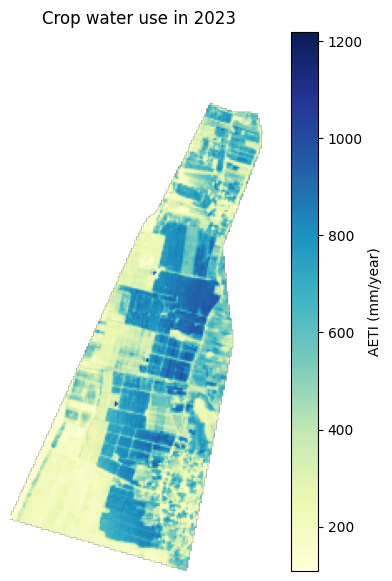

In [5]:
# Reference grid (AETI, 20 m) and annual water use in 2023
transform_ref, crs_ref, hauteur, largeur = grille_reference(2023)
aeti_2023, dates_2023 = lire_variable(2023, "L3-AETI-D")
dans_zone = ~np.isnan(aeti_2023[0])

total_2023 = np.sum(aeti_2023, axis=0)
print(f"Grid: {hauteur} × {largeur} pixels of 20 m")
print(f"AETI 2023: mean {np.nanmean(total_2023):.0f} mm, "
      f"min {np.nanmin(total_2023):.0f} mm, max {np.nanmax(total_2023):.0f} mm")

plt.figure(figsize=(6, 7))
plt.imshow(total_2023, cmap="YlGnBu")
plt.colorbar(label="AETI (mm/year)")
plt.title("Crop water use in 2023")
plt.axis("off")
plt.show()

### 2.2 Land cover: Esri / Impact Observatory 10 m
WaPOR LCC no longer exists in v3 (error 404 on `L2-LCC-A` and `L1-LCC-A`). The annual Esri map is used instead (collection `io-lulc-annual-v02` on the Microsoft Planetary Computer, available from 2018 to 2023), aggregated onto the 20 m grid using the **majority class**. Only maps whose start date matches the requested year are kept; 2024 and 2025 use the 2023 map.

Because the server limits the number of requests, this step is done **only once**: if the masks are already saved in the Drive (`masque_champ.npy`, `masque_serres.npy`), it is skipped and the server is not contacted.

In [6]:
# Esri maps: downloaded once, then read from the Drive
import time
fichier_lcc = dossier_projet + "/lcc_esri.npz"
bbox_gps = transform_bounds(crs_ref, "EPSG:4326", *array_bounds(hauteur, largeur, transform_ref))

def lire_esri(annee):
    """Esri map for the year (class codes) on the 20 m grid, or None if unavailable."""
    recherche = catalogue.search(collections=["io-lulc-annual-v02"], bbox=bbox_gps,
                                 datetime=f"{annee}-01-01/{annee}-12-31")
    items = [it for it in recherche.items()
             if it.properties.get("start_datetime", "")[:4] == str(annee)]
    if not items:
        return None
    carte = np.zeros((hauteur, largeur), dtype=np.uint8)
    for item in items:
        with rasterio.open(item.assets["data"].href) as src:
            b = transform_bounds("EPSG:4326", src.crs, *bbox_gps)
            fenetre = from_bounds(*b, transform=src.transform).round_offsets().round_lengths()
            morceau = src.read(1, window=fenetre, boundless=True, fill_value=0)
            temp = np.zeros_like(carte)
            reproject(source=morceau, destination=temp,
                      src_transform=src.window_transform(fenetre), src_crs=src.crs,
                      dst_transform=transform_ref, dst_crs=crs_ref,
                      resampling=Resampling.mode, src_nodata=0, dst_nodata=0)
        carte = np.where(carte == 0, temp, carte)
    carte[~dans_zone] = 0
    return carte

noms_esri = {1: "Water", 2: "Trees", 4: "Flooded vegetation", 5: "Crops",
             7: "Built area", 8: "Bare ground", 11: "Rangeland"}
couleurs_esri = {1: "#419bdf", 2: "#397d49", 4: "#7a87c6", 5: "#e49635",
                 7: "#c4281b", 8: "#a59b8f", 11: "#e3e2c3"}

fichiers_masques = [dossier_projet + "/masque_champ.npy", dossier_projet + "/masque_serres.npy"]
masques_deja_faits = all(os.path.exists(f) for f in fichiers_masques)

if masques_deja_faits:
    lcc_esri = {}
    print("✅ Masks already saved in the Drive: Esri step skipped (server not contacted)")
elif os.path.exists(fichier_lcc):
    archive = np.load(fichier_lcc)
    lcc_esri = {int(a): archive[a] for a in archive.files}
    print("✅ Esri maps read from the Drive:", sorted(lcc_esri))
else:
    for essai in range(5):
        try:
            catalogue = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                                  modifier=planetary_computer.sign_inplace)
            lcc_esri = {}
            for annee in annees:
                carte = lire_esri(annee)
                if carte is None:
                    print(f"❌ {annee} : not available")
                else:
                    lcc_esri[annee] = carte
            break
        except Exception as erreur:
            attente = 60 * (essai + 1)
            print(f"⏳ Server unavailable ({type(erreur).__name__}): retrying in {attente} s")
            time.sleep(attente)
    else:
        raise RuntimeError("Planetary Computer still unavailable: run this cell again later.")
    np.savez_compressed(fichier_lcc, **{str(a): c for a, c in lcc_esri.items()})
    print("✅ Esri maps saved in the Drive")

for annee, carte in sorted(lcc_esri.items()):
    total = np.sum(carte > 0)
    texte = " | ".join(f"{noms_esri[c]} {100 * np.sum(carte == c) / total:.1f} %"
                       for c in noms_esri if np.any(carte == c))
    print(f"✅ {annee} : {texte}")

if lcc_esri:
    derniere = max(lcc_esri)
    image = np.ones((hauteur, largeur, 3))
    for code_c, coul in couleurs_esri.items():
        image[lcc_esri[derniere] == code_c] = to_rgb(coul)
    plt.figure(figsize=(6, 7))
    plt.imshow(image)
    plt.legend(handles=[Patch(color=couleurs_esri[c], label=noms_esri[c]) for c in couleurs_esri
                        if np.any(lcc_esri[derniere] == c)], loc="lower right", fontsize=8)
    plt.title(f"Esri land cover, {derniere}")
    plt.axis("off")
    plt.show()

✅ Masks already saved in the Drive: Esri step skipped (server not contacted)


### 2.3 Masks: open field, greenhouses, exclusions
Compared with the satellite image, the Esri "built area" class mostly matches villages, while most **greenhouses** are classified as "crops". The 15 greenhouse blocks were therefore **digitised by hand** (geojson.io). Under plastic, the satellite sees the cover rather than the crop: greenhouses are analysed separately.

- **Open field** = Esri "crops" class, excluding greenhouses (one mask per year)
- **Excluded** = villages, dunes, bare ground, trees, water

✅ Masks read from the Drive
2018 : open field 61.5 % of the area
2019 : open field 60.6 % of the area
2020 : open field 61.9 % of the area
2021 : open field 59.0 % of the area
2022 : open field 68.7 % of the area
2023 : open field 73.2 % of the area
2024 : open field 73.2 % of the area
2025 : open field 73.2 % of the area
Greenhouses: 10.5 % of the area (85 ha)


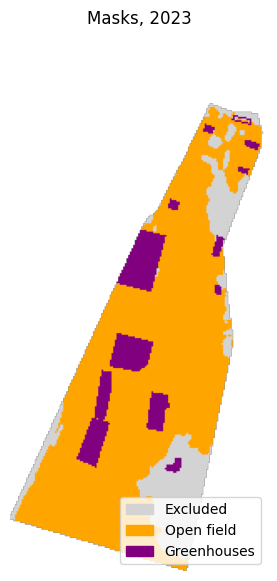

In [7]:
# "Open field" (yearly) and "greenhouse" (fixed) masks
if masques_deja_faits:
    serres = np.load(dossier_projet + "/masque_serres.npy")
    masque_champ = dict(zip(annees, np.load(dossier_projet + "/masque_champ.npy")))
    print("✅ Masks read from the Drive")
else:
    with open(fichier_serres) as f:
        geo = json.load(f)
    formes = [transform_geom("EPSG:4326", crs_ref, feat["geometry"]) for feat in geo["features"]]
    serres = rasterize(formes, out_shape=(hauteur, largeur), transform=transform_ref,
                       fill=0, default_value=1).astype(bool) & dans_zone
    print("Digitised greenhouses:", len(formes))
    masque_champ = {}
    for annee in annees:
        annee_esri = annee if annee in lcc_esri else min(lcc_esri, key=lambda a: abs(a - annee))
        masque_champ[annee] = (lcc_esri[annee_esri] == 5) & ~serres
    np.save(dossier_projet + "/masque_serres.npy", serres)
    np.save(dossier_projet + "/masque_champ.npy", np.array([masque_champ[a] for a in annees]))
    np.save(dossier_projet + "/dans_zone.npy", dans_zone)
    print("✅ Masks saved in the Drive")

for annee in annees:
    print(f"{annee} : open field {100 * masque_champ[annee].sum() / dans_zone.sum():.1f} % of the area")
print(f"Greenhouses: {100 * serres.sum() / dans_zone.sum():.1f} % of the area ({serres.sum() * 0.04:.0f} ha)")

categorie = np.full((hauteur, largeur), np.nan)
categorie[dans_zone] = 0
categorie[masque_champ[2023]] = 1
categorie[serres] = 2
plt.figure(figsize=(6, 7))
plt.imshow(categorie, cmap=ListedColormap(["lightgrey", "orange", "purple"]), vmin=0, vmax=2)
plt.legend(handles=[Patch(color="lightgrey", label="Excluded"),
                    Patch(color="orange", label="Open field"),
                    Patch(color="purple", label="Greenhouses")], loc="lower right")
plt.title("Masks, 2023")
plt.axis("off")
plt.show()

### 2.4 2018-2025 cubes and cropping seasons
Each variable is stacked into a cube of 288 dekads (8 years × 36). The analysis uses **cropping seasons** (September → August): 7 complete seasons, from 2018-19 to 2024-25.

In [8]:
# 2018-2025 cubes (computed once, then read from the Drive)
cubes = {}
for var in variables:
    chemin = f"{dossier_projet}/cube_{var}.npy"
    if os.path.exists(chemin):
        cubes[var] = np.load(chemin)
    else:
        cubes[var] = np.concatenate([lire_sur_grille(a, var)[0].astype(np.float32)
                                     for a in annees], axis=0)
        np.save(chemin, cubes[var])
    print(f"✅ {var} : {cubes[var].shape}")

dates_toutes = pd.to_datetime([f"{a}-{m:02d}-{j:02d}"
                               for a in annees for m in range(1, 13) for j in (1, 11, 21)])
masque_288 = np.repeat(np.array([masque_champ[a] for a in annees]), 36, axis=0)

campagne = np.where(dates_toutes.month >= 9, dates_toutes.year, dates_toutes.year - 1)
campagnes = list(range(2018, 2025))
nom_campagne = {c: f"{c}-{str(c + 1)[2:]}" for c in campagnes}
ete = dates_toutes.month.isin([6, 7, 8])
hiver = dates_toutes.month.isin([12, 1, 2])

aeti = cubes["L3-AETI-D"]
ret = cubes["L1-RET-D"]
pluie = cubes["L1-PCP-D"]
print("Seasons:", list(nom_campagne.values()))

✅ L3-AETI-D : (288, 324, 155)
✅ L3-NPP-D : (288, 324, 155)
✅ L1-RET-D : (288, 324, 155)
✅ L1-PCP-D : (288, 324, 155)
Seasons: ['2018-19', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']


## 3. The four indicators

### 3.1 Relative ET (AETI ÷ RET)
ETa ÷ ET0 = Kc × water satisfaction ratio: a low value may reflect a water deficit **or** low crop cover (young crop, harvested field). The 0.7 threshold suggested in the brief is first tested as is.

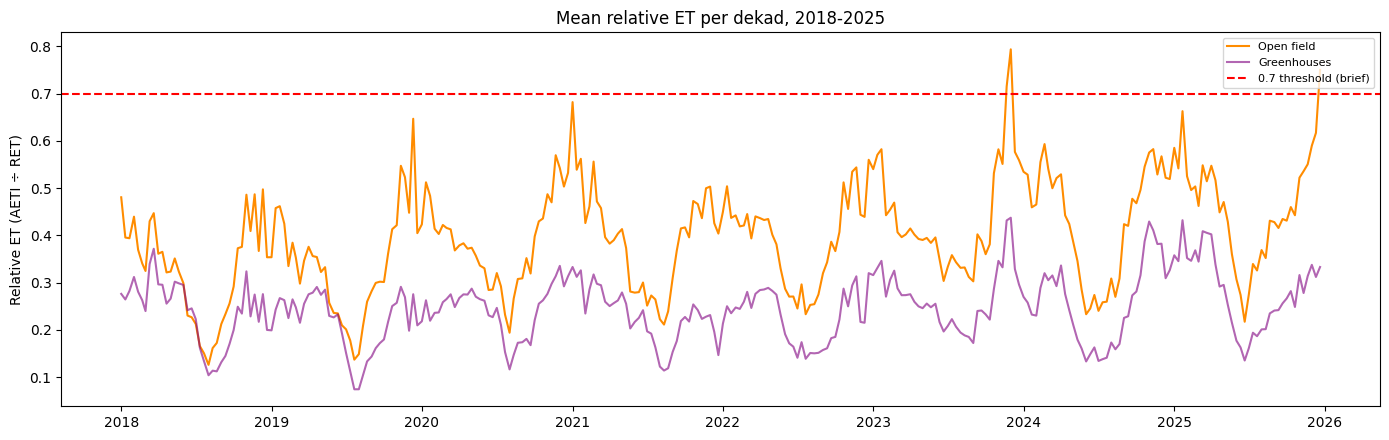

In [9]:
# Raw relative ET: open field and greenhouses
etrel = aeti / ret
etrel_champ = np.where(masque_288, etrel, np.nan)
etrel_serres = np.where(serres, etrel, np.nan)

plt.figure(figsize=(14, 4.5))
plt.plot(dates_toutes, np.nanmean(etrel_champ, axis=(1, 2)), color="darkorange", label="Open field")
plt.plot(dates_toutes, np.nanmean(etrel_serres, axis=(1, 2)), color="purple", alpha=0.6, label="Greenhouses")
plt.axhline(0.7, color="red", linestyle="--", label="0.7 threshold (brief)")
plt.ylabel("Relative ET (AETI ÷ RET)")
plt.title("Mean relative ET per dekad, 2018-2025")
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

Even the best fields stay below 0.7 in summer: the threshold does not suit this coastal area (RET probably overestimated by coarse pixels, drip-irrigated orchards with low Kc). Each pixel is therefore compared with the **best 5 % of open-field pixels in the same dekad** (95th percentile), which cancels out the error shared by all pixels on RET.

Mean reference in summer: 0.54 | in winter: 0.76


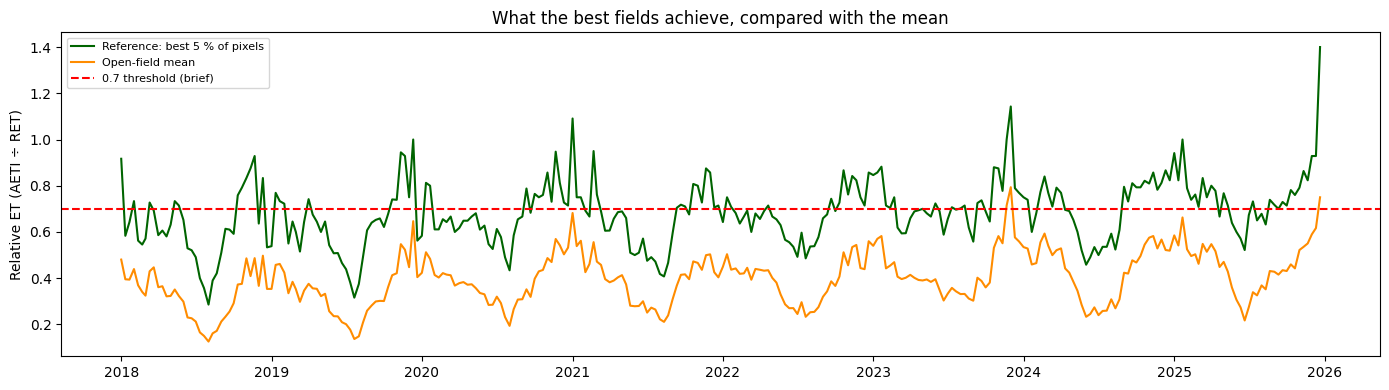

/tmp/ipykernel_2264/1466258780.py:18: RuntimeWarning: Mean of empty slice
  carte = np.nanmean(etrel_ref[ete & (campagne == c)], axis=0)


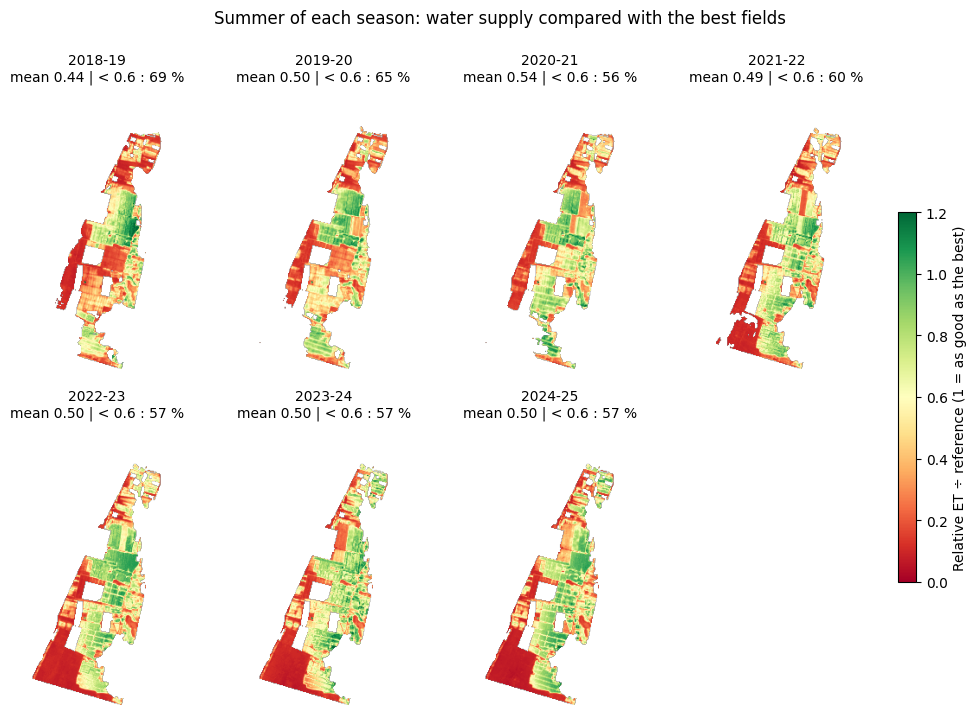

In [10]:
# Relative ET compared with the local reference (95th percentile)
reference = np.nanpercentile(etrel_champ, 95, axis=(1, 2))
etrel_ref = etrel_champ / reference[:, None, None]
print(f"Mean reference in summer: {np.mean(reference[ete]):.2f} | in winter: {np.mean(reference[hiver]):.2f}")

plt.figure(figsize=(14, 4))
plt.plot(dates_toutes, reference, color="darkgreen", label="Reference: best 5 % of pixels")
plt.plot(dates_toutes, np.nanmean(etrel_champ, axis=(1, 2)), color="darkorange", label="Open-field mean")
plt.axhline(0.7, color="red", linestyle="--", label="0.7 threshold (brief)")
plt.ylabel("Relative ET (AETI ÷ RET)")
plt.title("What the best fields achieve, compared with the mean")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for i, c in enumerate(campagnes):
    carte = np.nanmean(etrel_ref[ete & (campagne == c)], axis=0)
    pct_faible = 100 * np.sum(carte < 0.6) / np.sum(~np.isnan(carte))
    ax = axes.flat[i]
    im = ax.imshow(carte, cmap="RdYlGn", vmin=0, vmax=1.2)
    ax.set_title(f"{nom_campagne[c]}\nmean {np.nanmean(carte):.2f} | < 0.6 : {pct_faible:.0f} %", fontsize=10)
    ax.axis("off")
axes.flat[7].axis("off")
fig.colorbar(im, ax=axes, shrink=0.6, label="Relative ET ÷ reference (1 = as good as the best)")
plt.suptitle("Summer of each season: water supply compared with the best fields")
plt.show()

### 3.2 Estimated irrigation supply (AETI − effective rainfall)
Effective rainfall = 80 % of rainfall (simple FAO method), computed per dekad with no negative values. This is the irrigation water **consumed** by crops (net requirement met); the water actually withdrawn is higher.

         Rainfall (mm)  Water use AETI (mm)  Estimated irrigation (mm)  \
Season                                                                   
2018-19          461.0                388.0                      253.0   
2019-20          396.0                448.0                      299.0   
2020-21          757.0                442.0                      248.0   
2021-22          371.0                493.0                      342.0   
2022-23          436.0                540.0                      396.0   
2023-24          540.0                503.0                      327.0   
2024-25          382.0                556.0                      367.0   

         Irrigation (m³/ha)  
Season                       
2018-19              2526.0  
2019-20              2992.0  
2020-21              2484.0  
2021-22              3425.0  
2022-23              3964.0  
2023-24              3269.0  
2024-25              3668.0  


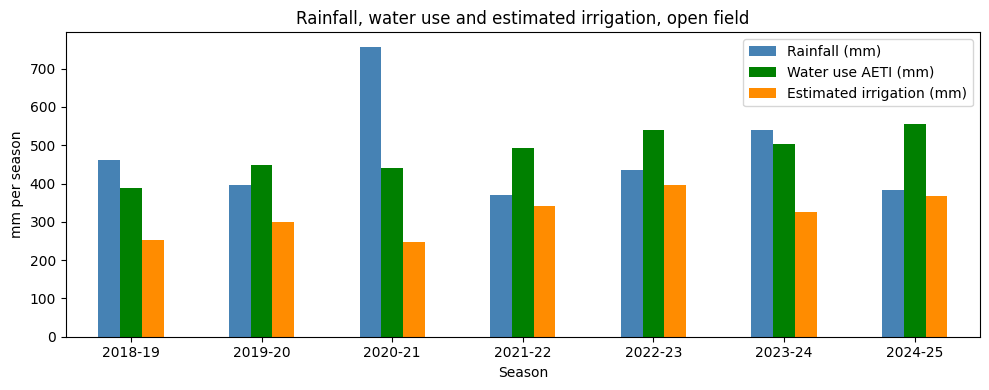

In [11]:
# Irrigation supply per season, open field
irrigation = np.maximum(aeti - 0.8 * pluie, 0)

def total_campagne(cube, c):
    """Season total, averaged over the open field (mm)."""
    sel = campagne == c
    return np.nanmean(np.sum(np.where(masque_288[sel], cube[sel], np.nan), axis=0))

tableau = pd.DataFrame([{"Season": nom_campagne[c],
                         "Rainfall (mm)": total_campagne(pluie, c),
                         "Water use AETI (mm)": total_campagne(aeti, c),
                         "Estimated irrigation (mm)": total_campagne(irrigation, c)}
                        for c in campagnes]).set_index("Season")
tableau["Irrigation (m³/ha)"] = tableau["Estimated irrigation (mm)"] * 10
print(tableau.round(0))

tableau.iloc[:, :3].plot(kind="bar", figsize=(10, 4), color=["steelblue", "green", "darkorange"])
plt.ylabel("mm per season")
plt.title("Rainfall, water use and estimated irrigation, open field")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.3 Water productivity (biomass ÷ AETI)
NPP (gC/m²) × 22.222 = total dry biomass (kg/ha), divided by water use (m³/ha). Absolute values include roots and should be interpreted with caution; comparisons between seasons are reliable.

In [12]:
# Water productivity per season, open field
biomasse = cubes["L3-NPP-D"] * 22.222
tab_pe = pd.DataFrame([{"Season": nom_campagne[c],
                        "Biomass (t/ha)": total_campagne(biomasse, c) / 1000,
                        "Water use (m³/ha)": total_campagne(aeti, c) * 10}
                       for c in campagnes]).set_index("Season")
tab_pe["Productivity (kg/m³)"] = tab_pe["Biomass (t/ha)"] * 1000 / tab_pe["Water use (m³/ha)"]
print(tab_pe.round(2))

         Biomass (t/ha)  Water use (m³/ha)  Productivity (kg/m³)
Season                                                          
2018-19       16.379999        3882.939941                  4.22
2019-20       19.620001        4479.490234                  4.38
2020-21       19.270000        4417.939941                  4.36
2021-22       20.580000        4934.390137                  4.17
2022-23       22.969999        5398.350098                  4.26
2023-24       22.639999        5034.080078                  4.50
2024-25       24.020000        5559.919922                  4.32


### 3.4 Uniformity (coefficient of variation of AETI between pixels)
Benchmarks: < 10 % good, 10-25 % fair, > 25 % poor. Computed here over the whole open field; it is recomputed over irrigated pixels only after the K-means (section 4).

In [13]:
# Coefficient of variation of water use between pixels, per season
lignes_cv = []
for c in campagnes:
    sel = campagne == c
    eau_pixel = np.sum(np.where(masque_288[sel], aeti[sel], np.nan), axis=0)
    lignes_cv.append({"Season": nom_campagne[c], "Mean (mm)": np.nanmean(eau_pixel),
                      "Std. dev. (mm)": np.nanstd(eau_pixel),
                      "CV (%)": 100 * np.nanstd(eau_pixel) / np.nanmean(eau_pixel)})
tab_cv = pd.DataFrame(lignes_cv).set_index("Season")
print(tab_cv.round(1))

          Mean (mm)  Std. dev. (mm)     CV (%)
Season                                        
2018-19  388.299988      192.699997  49.599998
2019-20  447.899994      199.399994  44.500000
2020-21  441.799988      175.500000  39.700001
2021-22  493.399994      202.899994  41.099998
2022-23  539.799988      248.500000  46.000000
2023-24  503.399994      206.199997  41.000000
2024-25  556.000000      262.200012  47.200001


## 4. Two-level K-means classification

**Level 1**: separate cropping systems (unproductive / rainfed / irrigated).
**Level 2**: within irrigated pixels only, classify water management.

Variables are standardised (z-score). The number of clusters is checked with the elbow method (inertia) and the silhouette coefficient.

In [14]:
# Per-pixel variables (means over the 7 seasons) and first check
liste_aeti, liste_ete, liste_irri, liste_hiver, liste_pe = [], [], [], [], []
for c in campagnes:
    sel = campagne == c
    m = masque_288[sel]
    eau_c = np.sum(np.where(m, aeti[sel], np.nan), axis=0)
    bio_c = np.sum(np.where(m, biomasse[sel], np.nan), axis=0)
    liste_aeti.append(eau_c)
    liste_irri.append(np.sum(np.where(m, irrigation[sel], np.nan), axis=0))
    liste_ete.append(np.nanmean(etrel_ref[sel & ete], axis=0))
    liste_hiver.append(np.nanmean(etrel_ref[sel & hiver], axis=0))
    liste_pe.append(np.where(eau_c * 10 > 1000, bio_c / (eau_c * 10), np.nan))

carte_aeti = np.nanmean(liste_aeti, axis=0)
carte_irri = np.nanmean(liste_irri, axis=0)
carte_ete = np.nanmean(liste_ete, axis=0)
carte_hiver = np.nanmean(liste_hiver, axis=0)
carte_pe = np.nanmedian(liste_pe, axis=0)

# First attempt: AETI, summer ET, irrigation -> redundant variables
ok = ~np.isnan(carte_aeti) & ~np.isnan(carte_ete) & ~np.isnan(carte_irri)
X0 = np.column_stack([carte_aeti[ok], carte_ete[ok], carte_irri[ok]])
noms0 = ["AETI", "Summer rel. ET / ref.", "Irrigation"]
print("Correlation (first attempt):")
print(pd.DataFrame(np.corrcoef(X0.T), index=noms0, columns=noms0).round(2))

/tmp/ipykernel_2264/3993590104.py:10: RuntimeWarning: Mean of empty slice
  liste_ete.append(np.nanmean(etrel_ref[sel & ete], axis=0))
/tmp/ipykernel_2264/3993590104.py:11: RuntimeWarning: Mean of empty slice
  liste_hiver.append(np.nanmean(etrel_ref[sel & hiver], axis=0))


Correlation (first attempt):
                       AETI  Summer rel. ET / ref.  Irrigation
AETI                   1.00                   0.97        1.00
Summer rel. ET / ref.  0.97                   1.00        0.98
Irrigation             1.00                   0.98        1.00


/tmp/ipykernel_2264/3993590104.py:14: RuntimeWarning: Mean of empty slice
  carte_aeti = np.nanmean(liste_aeti, axis=0)
/tmp/ipykernel_2264/3993590104.py:15: RuntimeWarning: Mean of empty slice
  carte_irri = np.nanmean(liste_irri, axis=0)
/tmp/ipykernel_2264/3993590104.py:16: RuntimeWarning: Mean of empty slice
  carte_ete = np.nanmean(liste_ete, axis=0)
/tmp/ipykernel_2264/3993590104.py:17: RuntimeWarning: Mean of empty slice
  carte_hiver = np.nanmean(liste_hiver, axis=0)
/tmp/ipykernel_2264/3993590104.py:18: RuntimeWarning: All-NaN slice encountered
  carte_pe = np.nanmedian(liste_pe, axis=0)


The first three variables are correlated at 0.97-1.00: the K-means would only split a single axis. They are replaced by three complementary variables: **summer relative ET**, **winter relative ET** (seasonal profile) and **water productivity** (median over seasons, computed only above 1,000 m³/ha).

In [15]:
# Level 1: cropping systems
valides = ~np.isnan(carte_ete) & ~np.isnan(carte_hiver) & ~np.isnan(carte_pe)
noms_var = ["Summer rel. ET / ref.", "Winter rel. ET / ref.", "Productivity (kg/m³)"]
X = np.column_stack([carte_ete[valides], carte_hiver[valides], carte_pe[valides]])
print("Correlation:")
print(pd.DataFrame(np.corrcoef(X.T), index=noms_var, columns=noms_var).round(2))

X_std = StandardScaler().fit_transform(X)
inertie_totale = np.sum(X_std ** 2)
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_std)
    s = silhouette_score(X_std, km_k.labels_, sample_size=5000, random_state=0)
    print(f"k = {k} : silhouette = {s:.3f} | explained variance = {100 * (1 - km_k.inertia_ / inertie_totale):.1f} %")

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_std)
ordre = np.argsort([X[km.labels_ == g, 0].mean() for g in range(3)])
groupes = np.zeros_like(km.labels_)
for nouveau, ancien in enumerate(ordre):
    groupes[km.labels_ == ancien] = nouveau + 1

profil = pd.DataFrame(X, columns=noms_var)
profil["AETI (mm/year)"] = carte_aeti[valides]
profil["Cluster"] = groupes
resume = profil.groupby("Cluster").mean()
resume["Area (%)"] = 100 * profil["Cluster"].value_counts(normalize=True).sort_index()
resume.index = ["1 Low-productivity land", "2 Rainfed winter crops", "3 Irrigated crops"]
print("\nMean cluster profile:")
print(resume.round(2))

carte_groupes = np.full((hauteur, largeur), np.nan)
carte_groupes[valides] = groupes

Correlation:
                       Summer rel. ET / ref.  Winter rel. ET / ref.  \
Summer rel. ET / ref.                   1.00                   0.86   
Winter rel. ET / ref.                   0.86                   1.00   
Productivity (kg/m³)                    0.17                   0.40   

                       Productivity (kg/m³)  
Summer rel. ET / ref.                  0.17  
Winter rel. ET / ref.                  0.40  
Productivity (kg/m³)                   1.00  
k = 2 : silhouette = 0.499 | explained variance = 50.5 %
k = 3 : silhouette = 0.518 | explained variance = 68.2 %
k = 4 : silhouette = 0.395 | explained variance = 75.1 %
k = 5 : silhouette = 0.401 | explained variance = 79.6 %
k = 6 : silhouette = 0.400 | explained variance = 83.2 %

Mean cluster profile:
                         Summer rel. ET / ref.  Winter rel. ET / ref.  \
1 Low-productivity land                   0.16                   0.27   
2 Rainfed winter crops                    0.21                  

Irrigated pixels: 8307 | correlation: -0.27
k = 2 : silhouette = 0.366 | explained variance = 40.1 %
k = 3 : silhouette = 0.426 | explained variance = 62.0 %
k = 4 : silhouette = 0.362 | explained variance = 70.0 %
k = 5 : silhouette = 0.376 | explained variance = 76.8 %
k = 6 : silhouette = 0.353 | explained variance = 80.5 %

Mean profile of irrigated sub-clusters:
                            Summer rel. ET / ref.  Productivity (kg/m³)  \
1 Frugal, efficient                          0.56                  4.56   
2 Poorly valued water                        0.64                  3.99   
3 Well supplied, intensive                   0.78                  4.38   

                            AETI (mm/year)  Irrigation (m³/ha)  Area (%)  
1 Frugal, efficient             546.409973         3670.159912     35.74  
2 Poorly valued water           557.369995         3841.139893     19.01  
3 Well supplied, intensive      694.960022         4995.049805     45.25  

AETI coefficient of variatio

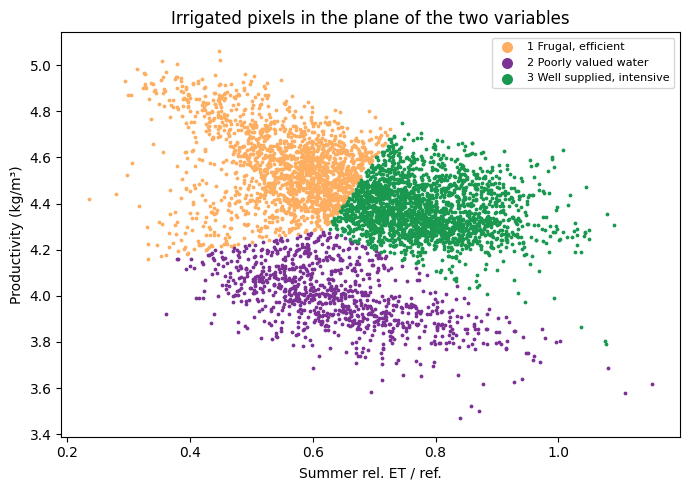

In [16]:
# Level 2: water management of irrigated pixels
irrigue = np.zeros((hauteur, largeur), dtype=bool)
irrigue[valides] = (groupes == 3)
pluvial = np.zeros((hauteur, largeur), dtype=bool)
pluvial[valides] = (groupes == 2)

noms2 = ["Summer rel. ET / ref.", "Productivity (kg/m³)"]
X2 = np.column_stack([carte_ete[irrigue], carte_pe[irrigue]])
print(f"Irrigated pixels: {X2.shape[0]} | correlation: {np.corrcoef(X2.T)[0, 1]:.2f}")

X2_std = StandardScaler().fit_transform(X2)
inertie_tot2 = np.sum(X2_std ** 2)
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X2_std)
    s = silhouette_score(X2_std, km_k.labels_, sample_size=5000, random_state=0)
    print(f"k = {k} : silhouette = {s:.3f} | explained variance = {100 * (1 - km_k.inertia_ / inertie_tot2):.1f} %")

km2 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X2_std)
ordre2 = np.argsort([X2[km2.labels_ == g, 0].mean() for g in range(3)])
sous_groupes = np.zeros_like(km2.labels_)
for nouveau, ancien in enumerate(ordre2):
    sous_groupes[km2.labels_ == ancien] = nouveau + 1

profil2 = pd.DataFrame(X2, columns=noms2)
profil2["AETI (mm/year)"] = carte_aeti[irrigue]
profil2["Irrigation (m³/ha)"] = carte_irri[irrigue] * 10
profil2["Sub-cluster"] = sous_groupes
resume2 = profil2.groupby("Sub-cluster").mean()
resume2["Area (%)"] = 100 * profil2["Sub-cluster"].value_counts(normalize=True).sort_index()
resume2.index = ["1 Frugal, efficient", "2 Poorly valued water", "3 Well supplied, intensive"]
print("\nMean profile of irrigated sub-clusters:")
print(resume2.round(2))

print("\nAETI coefficient of variation per season:")
for c, aeti_c in zip(campagnes, liste_aeti):
    cv_tout = 100 * np.nanstd(aeti_c) / np.nanmean(aeti_c)
    cv_irr = 100 * np.nanstd(aeti_c[irrigue]) / np.nanmean(aeti_c[irrigue])
    print(f"  {nom_campagne[c]} : open field {cv_tout:.0f} % | irrigated only {cv_irr:.0f} %")

carte_sg = np.full((hauteur, largeur), np.nan)
carte_sg[irrigue] = sous_groupes

couleurs_sg = ["#fdae61", "#7b3294", "#1a9850"]
ech = np.random.default_rng(0).choice(len(X2), size=min(5000, len(X2)), replace=False)
plt.figure(figsize=(7, 5))
for g, (coul, nom) in enumerate(zip(couleurs_sg, resume2.index), start=1):
    pts = ech[sous_groupes[ech] == g]
    plt.scatter(X2[pts, 0], X2[pts, 1], s=3, color=coul, label=nom)
plt.xlabel(noms2[0])
plt.ylabel(noms2[1])
plt.title("Irrigated pixels in the plane of the two variables")
plt.legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.show()

## 5. Key figures

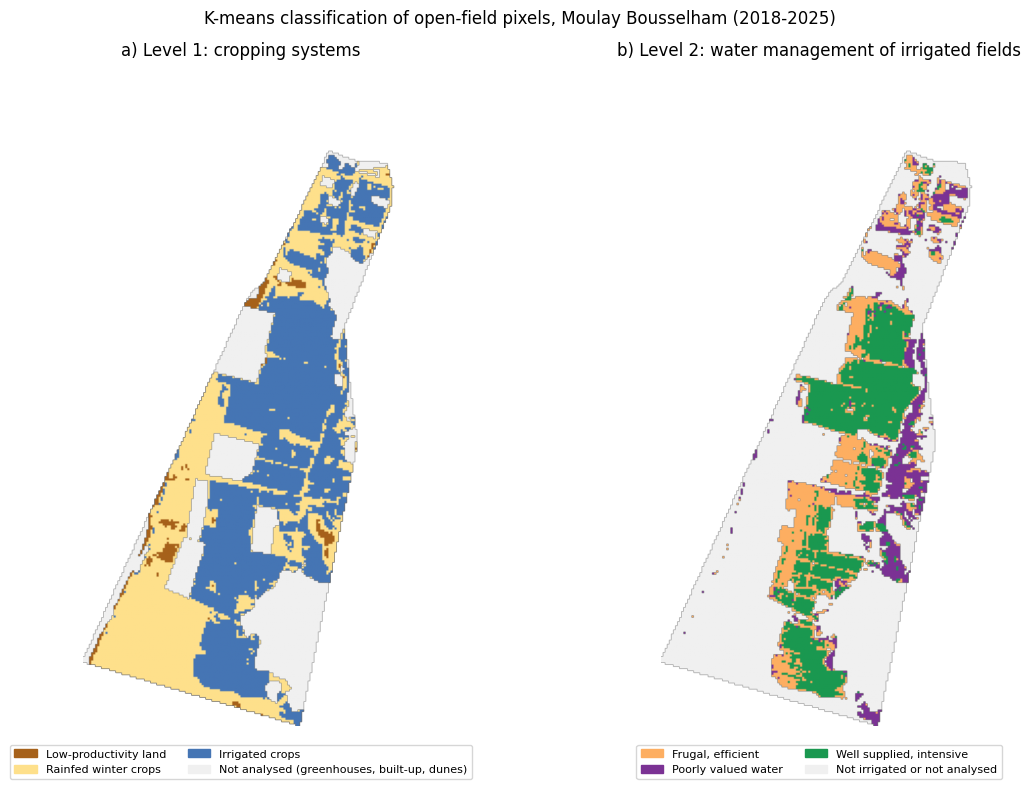

In [17]:
# Figure 1: cluster map (two-level K-means)
noms_n1 = ["Low-productivity land", "Rainfed winter crops", "Irrigated crops"]
coul_n1 = ["#a6611a", "#fee08b", "#4575b4"]
noms_n2 = ["Frugal, efficient", "Poorly valued water", "Well supplied, intensive"]
coul_n2 = ["#fdae61", "#7b3294", "#1a9850"]

fond = np.where(dans_zone, 0, np.nan)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))

ax1.imshow(fond, cmap=ListedColormap(["#f0f0f0"]))
ax1.imshow(carte_groupes, cmap=ListedColormap(coul_n1), vmin=1, vmax=3)
ax1.legend(handles=[Patch(color=c, label=n) for c, n in zip(coul_n1, noms_n1)]
           + [Patch(color="#f0f0f0", label="Not analysed (greenhouses, built-up, dunes)")],
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=8)
ax1.set_title("a) Level 1: cropping systems")
ax1.axis("off")

ax2.imshow(fond, cmap=ListedColormap(["#f0f0f0"]))
ax2.imshow(carte_sg, cmap=ListedColormap(coul_n2), vmin=1, vmax=3)
ax2.legend(handles=[Patch(color=c, label=n) for c, n in zip(coul_n2, noms_n2)]
           + [Patch(color="#f0f0f0", label="Not irrigated or not analysed")],
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=8)
ax2.set_title("b) Level 2: water management of irrigated fields")
ax2.axis("off")

plt.suptitle("K-means classification of open-field pixels, Moulay Bousselham (2018-2025)")
plt.tight_layout()
plt.savefig(dossier_projet + "/figure1_cluster_map.png", dpi=200, bbox_inches="tight")
plt.show()

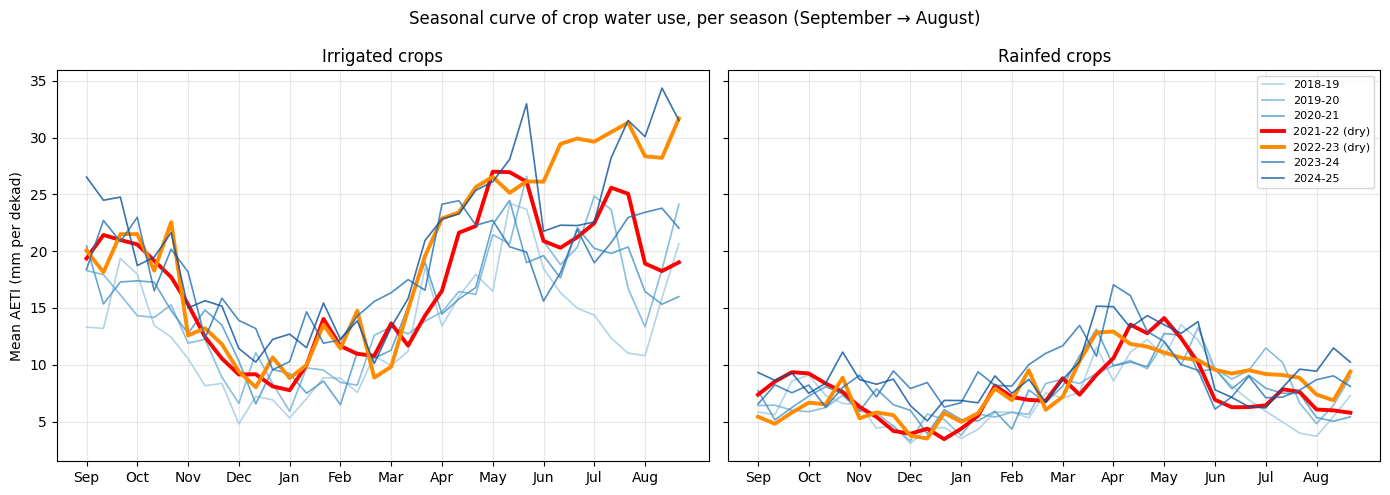

In [18]:
# Figure 2: seasonal curve per season, irrigated vs rainfed
mois_campagne = ["Sep", "Oct", "Nov", "Dec", "Jan", "Feb",
                 "Mar", "Apr", "May", "Jun", "Jul", "Aug"]
couleurs_c = {2018: "#9ecae1", 2019: "#6baed6", 2020: "#4292c6",
              2021: "red", 2022: "darkorange", 2023: "#2171b5", 2024: "#08519c"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, masque, titre in [(axes[0], irrigue, "Irrigated crops"),
                          (axes[1], pluvial, "Rainfed crops")]:
    for c in campagnes:
        indices = np.where(campagne == c)[0]
        serie = [np.nanmean(aeti[i][masque]) for i in indices]
        epais = c in (2021, 2022)
        ax.plot(range(36), serie, color=couleurs_c[c], lw=2.8 if epais else 1.2,
                alpha=1 if epais else 0.8, label=nom_campagne[c] + (" (dry)" if epais else ""))
    ax.set_xticks(range(0, 36, 3))
    ax.set_xticklabels(mois_campagne)
    ax.set_title(titre)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean AETI (mm per dekad)")
axes[1].legend(fontsize=8)
plt.suptitle("Seasonal curve of crop water use, per season (September → August)")
plt.tight_layout()
plt.savefig(dossier_projet + "/figure2_seasonal_curve.png", dpi=200, bbox_inches="tight")
plt.show()

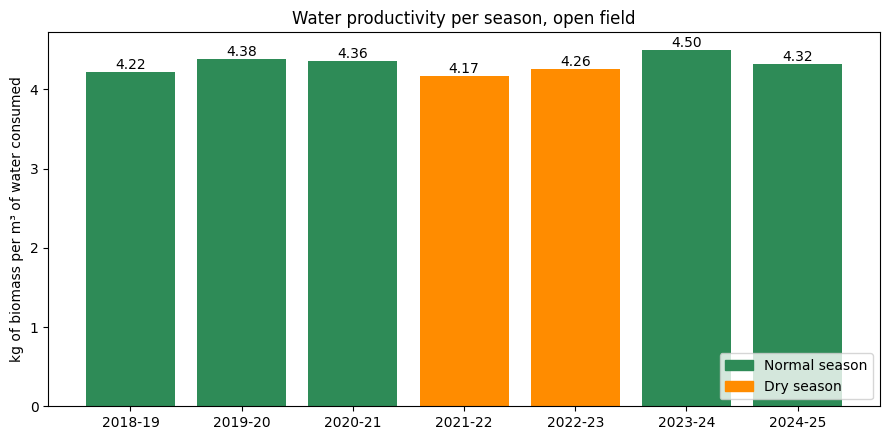

✅ Figures saved in /content/drive/MyDrive/Projet_WaPOR


In [19]:
# Figure 3: water productivity per season
couleurs_barres = ["darkorange" if c in (2021, 2022) else "seagreen" for c in campagnes]
plt.figure(figsize=(9, 4.5))
barres = plt.bar(tab_pe.index, tab_pe["Productivity (kg/m³)"], color=couleurs_barres)
plt.bar_label(barres, fmt="%.2f")
plt.legend(handles=[Patch(color="seagreen", label="Normal season"),
                    Patch(color="darkorange", label="Dry season")], loc="lower right")
plt.ylabel("kg of biomass per m³ of water consumed")
plt.title("Water productivity per season, open field")
plt.tight_layout()
plt.savefig(dossier_projet + "/figure3_water_productivity.png", dpi=200, bbox_inches="tight")
plt.show()
print("✅ Figures saved in", dossier_projet)

## 6. Conclusions and limitations

### Answer to the research question
- **Where?** The open field is split between an **irrigated core** in the centre (≈ 55 % of classified pixels) and **rainfed winter crops** to the west and south-west (≈ 43 %). Among irrigated pixels: 45 % **well supplied**, 36 % **frugal and efficient**, 19 % with **poorly valued water**, mostly along the lagoon.
- **When?** Differences arise **from May to August** and only for irrigated crops; in winter, rainfall and low climatic demand make conditions similar.
- **Enough, too much, too little?** No widespread shortage: during the drought, irrigation **compensated** for the rainfall deficit (2021-22: rainfall halved, irrigation + 38 %). Water use rises throughout the period (≈ 3,900 → 5,600 m³/ha), with **stable** water productivity (4.2-4.5 kg/m³), slightly lower in dry years. Uniformity among irrigated fields improves (CV from 39 % to ≈ 20 %).
- **The drought at the season scale.** Summer 2022: irrigation drops from June onwards. Summer 2023: it is kept at the highest level of the period.

### Methodological choices
- Esri land cover (LCC missing from WaPOR v3) and manual digitisation of greenhouses.
- Analysis by cropping season (September → August).
- 0.7 threshold replaced by a local reference (95th percentile), since even the best fields do not reach it in summer.
- Two-level K-means on non-redundant variables, validated by the elbow method and the silhouette (0.52 and 0.43).

### Limitations
- Coarse-resolution RET and rainfall (one value per dekad for the whole area); RET probably overestimated near the coast.
- AETI underestimated under greenhouses: greenhouses excluded from the indicators.
- WaPOR biomass is total biomass (roots included): absolute productivity values should be read with caution.
- No Esri map for 2024-2025 (2023 map reused) and a classification change in 2022-2023.
- Study area delineated visually, without the official boundaries of the irrigation scheme (ORMVA du Loukkos).
- Estimated irrigation = water consumed; water withdrawn (groundwater) is not observed.